
# Movie Recommendation System

The Movie Recommendation System is a machine learning project designed to recommend movies to users based on their interests and previous rating patterns. This project uses the MovieLens dataset, which contains movie details, user ratings, genres, and tags.

The system combines **Content-Based Filtering** and **Item-Based Collaborative Filtering** to generate personalized movie recommendations. TF-IDF Vectorization and Cosine Similarity are used to identify similar movies, while user rating patterns help predict movie preferences.

A Hybrid Recommendation Model is also implemented by combining both approaches to improve recommendation quality. The models are evaluated using Root Mean Squared Error (RMSE).

**Objectives:**
- Explore and preprocess the MovieLens dataset.
- Analyze movie ratings and popularity.
- Implement Content-Based Filtering.
- Implement Item-Based Collaborative Filtering.
- Develop a Hybrid Recommendation System.
- Evaluate model performance using RMSE.
- Generate personalized movie recommendations for users.

**Dataset:** MovieLens (ml-latest-small)

**Technologies Used:** Python, NumPy, Pandas, Matplotlib, Seaborn, Scikit-learn and SciPy.


In [3]:
# Import the libraries needed to prepare the movie data, build recommendation models, and evaluate their results.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import csr_matrix
import warnings
warnings.filterwarnings("ignore")


In [4]:
# Load the MovieLens files and combine genres and tags into one metadata field for each movie.
movies = pd.read_csv("movies.csv")
ratings = pd.read_csv("ratings.csv")
tags = pd.read_csv("tags.csv")
links = pd.read_csv("links.csv")

movies["genres_clean"] = (
    movies["genres"].fillna("").str.replace("|", " ", regex=False)
    .str.replace("-", " ", regex=False).str.lower()
)

tags_clean = tags.copy()
tags_clean["tag_clean"] = tags_clean["tag"].fillna("").astype(str).str.lower().str.strip()
tags_grouped = (
    tags_clean.groupby("movieId")["tag_clean"]
    .apply(lambda values: " ".join(value for value in values if value))
    .reset_index()
)

movies_enriched = movies.merge(tags_grouped, on="movieId", how="left")
movies_enriched["tag_clean"] = movies_enriched["tag_clean"].fillna("")
movies_enriched["metadata_soup"] = (
    movies_enriched["genres_clean"] + " " + movies_enriched["tag_clean"]
).str.strip()

n_users = ratings["userId"].nunique()
n_movies = ratings["movieId"].nunique()
n_ratings = len(ratings)
sparsity = (1 - n_ratings / (n_users * n_movies)) * 100

print(f"Loaded {n_ratings} ratings from {n_users} users across {n_movies} movies.")
print(f"Matrix Sparsity: {sparsity:.2f}%")


Loaded 100836 ratings from 610 users across 9724 movies.
Matrix Sparsity: 98.30%


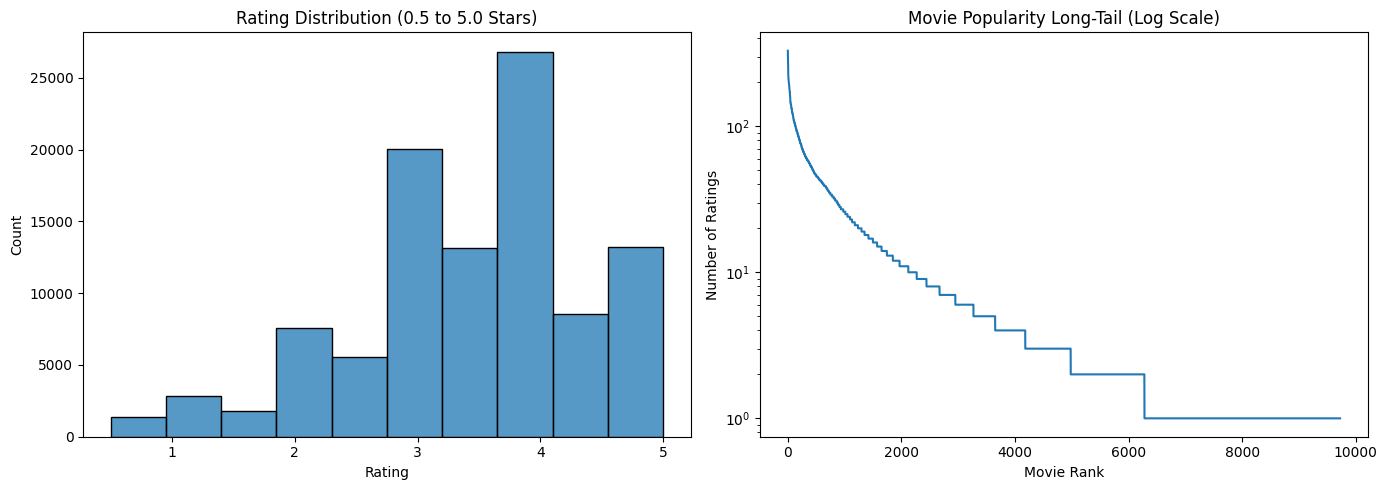

In [5]:
# Explore the rating distribution and see how movie popularity is spread across the dataset.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(ratings["rating"], bins=10, kde=False, ax=axes[0])
axes[0].set_title("Rating Distribution (0.5 to 5.0 Stars)")
axes[0].set_xlabel("Rating")
axes[0].set_ylabel("Count")

movie_counts = ratings["movieId"].value_counts().values
axes[1].plot(movie_counts)
axes[1].set_yscale("log")
axes[1].set_title("Movie Popularity Long-Tail (Log Scale)")
axes[1].set_xlabel("Movie Rank")
axes[1].set_ylabel("Number of Ratings")

plt.tight_layout()
plt.show()


In [6]:
# Split the ratings into training and testing data, then calculate a simple user-average baseline.
train_ratings, test_ratings = train_test_split(
    ratings, test_size=0.2, random_state=42
)
train_ratings = train_ratings.copy()
test_ratings = test_ratings.copy()

global_mean = float(train_ratings["rating"].mean())
user_means = train_ratings.groupby("userId")["rating"].mean().to_dict()
item_means = train_ratings.groupby("movieId")["rating"].mean().to_dict()

def clip_rating(value):
    return float(np.clip(value, 0.5, 5.0))

test_user_mean = (
    test_ratings["userId"].map(user_means).fillna(global_mean).clip(0.5, 5.0)
)
baseline_rmse = float(np.sqrt(np.mean((test_ratings["rating"] - test_user_mean) ** 2)))

print(f"Global Mean Rating: {global_mean:.4f}")
print(f"User Mean Baseline Test RMSE: {baseline_rmse:.4f}")


Global Mean Rating: 3.5026
User Mean Baseline Test RMSE: 0.9497


In [7]:
# Build a TF-IDF content-based model that predicts ratings using similarities between movie descriptions.
tfidf = TfidfVectorizer(
    ngram_range=(1, 2), min_df=1, stop_words="english"
)
tfidf_matrix = tfidf.fit_transform(movies_enriched["metadata_soup"])

movie_to_idx = {
    movie_id: idx for idx, movie_id in enumerate(movies_enriched["movieId"])
}
idx_to_movie = {
    idx: movie_id for movie_id, idx in movie_to_idx.items()
}

item_cb_sim = cosine_similarity(
    tfidf_matrix, tfidf_matrix, dense_output=False
).tocsr()

def predict_content_based(user_id, movie_id, history=train_ratings):
    if movie_id not in movie_to_idx:
        return clip_rating(user_means.get(user_id, global_mean))

    user_history = history[history["userId"] == user_id]
    user_mean = user_means.get(user_id, global_mean)

    if user_history.empty:
        return clip_rating(user_mean)

    target_idx = movie_to_idx[movie_id]
    rated_indices = user_history["movieId"].map(movie_to_idx)
    valid_mask = rated_indices.notna()

    if not valid_mask.any():
        return clip_rating(user_mean)

    rated_indices = rated_indices[valid_mask].astype(int).to_numpy()
    rated_values = user_history.loc[valid_mask, "rating"].to_numpy(dtype=float)
    similarities = item_cb_sim.getrow(target_idx).toarray().ravel()[rated_indices]
    useful = similarities > 0

    if not np.any(useful):
        return clip_rating(user_mean)

    weights = similarities[useful]
    rating_differences = rated_values[useful] - user_mean
    prediction = user_mean + np.dot(weights, rating_differences) / weights.sum()
    return clip_rating(prediction)

print("Sparse TF-IDF Content-Based Model Built Successfully!")


Sparse TF-IDF Content-Based Model Built Successfully!


In [8]:
# Build an item-based collaborative filtering model using similarities in users' rating patterns.
def build_item_cf_model(rating_data):
    user_ids = pd.Index(rating_data["userId"].unique())
    movie_ids = pd.Index(rating_data["movieId"].unique())

    user_index = {user_id: idx for idx, user_id in enumerate(user_ids)}
    movie_index = {movie_id: idx for idx, movie_id in enumerate(movie_ids)}

    row_indices = rating_data["userId"].map(user_index).to_numpy()
    col_indices = rating_data["movieId"].map(movie_index).to_numpy()

    user_average = rating_data.groupby("userId")["rating"].mean()
    centered_values = (
        rating_data["rating"].to_numpy(dtype=float)
        - rating_data["userId"].map(user_average).to_numpy(dtype=float)
    )

    user_item_matrix = csr_matrix(
        (centered_values, (row_indices, col_indices)),
        shape=(len(user_ids), len(movie_ids))
    )

    similarity_matrix = cosine_similarity(
        user_item_matrix.T, dense_output=False
    ).tocsr()

    rating_counts = rating_data["movieId"].value_counts().to_dict()

    return {
        "similarity": similarity_matrix,
        "movie_index": movie_index,
        "movie_ids": movie_ids,
        "rating_counts": rating_counts
    }

cf_model = build_item_cf_model(train_ratings)
item_rating_counts = cf_model["rating_counts"]

def predict_item_cf(user_id, movie_id, model=cf_model, k=20):
    user_mean = user_means.get(user_id, global_mean)
    target_idx = model["movie_index"].get(movie_id)

    if target_idx is None:
        return clip_rating(user_mean)

    user_history = train_ratings[train_ratings["userId"] == user_id]
    if user_history.empty:
        return clip_rating(user_mean)

    rated = user_history[
        user_history["movieId"].isin(model["movie_index"])
        & (user_history["movieId"] != movie_id)
    ]

    if rated.empty:
        return clip_rating(user_mean)

    rated_indices = rated["movieId"].map(model["movie_index"]).to_numpy()
    similarities = model["similarity"].getrow(target_idx).toarray().ravel()[rated_indices]
    useful = similarities > 0

    if not np.any(useful):
        return clip_rating(user_mean)

    similarities = similarities[useful]
    rated_values = rated["rating"].to_numpy(dtype=float)[useful]

    best = np.argsort(similarities)[-k:]
    weights = similarities[best]
    rating_differences = rated_values[best] - user_mean

    if weights.sum() == 0:
        return clip_rating(user_mean)

    prediction = user_mean + np.dot(weights, rating_differences) / weights.sum()
    return clip_rating(prediction)

print("Sparse Mean-Centred Item Collaborative Filtering Model Built Successfully!")


Sparse Mean-Centred Item Collaborative Filtering Model Built Successfully!


In [9]:
# Combine content-based and collaborative predictions, giving more weight to items with enough ratings.
def predict_dynamic_hybrid(user_id, movie_id, model=cf_model, history=train_ratings, gamma=10):
    item_count = model["rating_counts"].get(movie_id, 0)
    alpha = item_count / (item_count + gamma) if item_count + gamma > 0 else 0

    prediction_cf = predict_item_cf(user_id, movie_id, model=model)
    prediction_cb = predict_content_based(user_id, movie_id, history=history)

    hybrid_prediction = alpha * prediction_cf + (1 - alpha) * prediction_cb
    return clip_rating(hybrid_prediction)

print("Dynamic Hybrid Recommendation Engine Ready!")


Dynamic Hybrid Recommendation Engine Ready!


In [10]:
# Test how the recommendation methods behave when selected movies have no rating history in the training data.
sample_size = min(200, len(test_ratings))
cold_test_sample = test_ratings.sample(n=sample_size, random_state=42).copy()

cold_movie_ids = cold_test_sample["movieId"].unique()
cold_train_ratings = train_ratings[
    ~train_ratings["movieId"].isin(cold_movie_ids)
].copy()

cold_cf_model = build_item_cf_model(cold_train_ratings)

cold_cf_predictions = []
cold_hybrid_predictions = []

for row in cold_test_sample.itertuples(index=False):
    user_id = int(row.userId)
    movie_id = int(row.movieId)

    cf_prediction = predict_item_cf(user_id, movie_id, model=cold_cf_model)
    hybrid_prediction = predict_dynamic_hybrid(
        user_id, movie_id, model=cold_cf_model, history=train_ratings
    )

    cold_cf_predictions.append(cf_prediction)
    cold_hybrid_predictions.append(hybrid_prediction)

cold_test_sample["cf_prediction"] = cold_cf_predictions
cold_test_sample["hybrid_prediction"] = cold_hybrid_predictions

cold_cf_rmse = np.sqrt(
    np.mean((cold_test_sample["rating"] - cold_test_sample["cf_prediction"]) ** 2)
)
cold_hybrid_rmse = np.sqrt(
    np.mean((cold_test_sample["rating"] - cold_test_sample["hybrid_prediction"]) ** 2)
)

print("=== SIMULATED COLD-ITEM RESULTS ===")
print(f"Movies held out from CF training: {len(cold_movie_ids)}")
print(f"Collaborative Filtering RMSE: {cold_cf_rmse:.4f}")
print(f"Content + Collaborative Hybrid RMSE: {cold_hybrid_rmse:.4f}")
print("For held-out movies, collaborative filtering falls back to the user's mean.")
print("The hybrid can still use movie genres and tags through content-based filtering.")


=== SIMULATED COLD-ITEM RESULTS ===
Movies held out from CF training: 189
Collaborative Filtering RMSE: 0.9636
Content + Collaborative Hybrid RMSE: 0.9201
For held-out movies, collaborative filtering falls back to the user's mean.
The hybrid can still use movie genres and tags through content-based filtering.


In [11]:
# Compare the honest evaluation pipeline with a deliberately leaky baseline using exactly the same test records.
eval_sample = test_ratings.sample(
    n=min(1000, len(test_ratings)), random_state=42
).copy()

honest_predictions = [
    predict_dynamic_hybrid(int(row.userId), int(row.movieId))
    for row in eval_sample.itertuples(index=False)
]
honest_rmse = np.sqrt(
    np.mean((eval_sample["rating"].to_numpy() - np.array(honest_predictions)) ** 2)
)

sample_user_means = eval_sample["userId"].map(user_means).fillna(global_mean)
baseline_sample_rmse = np.sqrt(
    np.mean((eval_sample["rating"].to_numpy() - sample_user_means.to_numpy()) ** 2)
)

full_user_means = ratings.groupby("userId")["rating"].mean().to_dict()
leaky_predictions = np.array([
    clip_rating(full_user_means.get(int(user_id), global_mean))
    for user_id in eval_sample["userId"]
])
leaky_rmse = np.sqrt(
    np.mean((eval_sample["rating"].to_numpy() - leaky_predictions) ** 2)
)

results_df = pd.DataFrame({
    "Model Pipeline": [
        "User Mean Baseline (Same Sample)",
        "Leaky User Mean (For Demonstration)",
        "Honest Dynamic Hybrid"
    ],
    "Test RMSE": [
        baseline_sample_rmse, leaky_rmse, honest_rmse
    ],
    "Evaluation Note": [
        "Uses training ratings only",
        "Uses all ratings, including test targets",
        "Uses training ratings and movie metadata only"
    ]
})

print(results_df.to_string(index=False))
print("\nThe leaky result is shown only to demonstrate data leakage and is not a valid test score.")


                     Model Pipeline  Test RMSE                               Evaluation Note
   User Mean Baseline (Same Sample)   0.955517                    Uses training ratings only
Leaky User Mean (For Demonstration)   0.948346      Uses all ratings, including test targets
              Honest Dynamic Hybrid   0.865258 Uses training ratings and movie metadata only

The leaky result is shown only to demonstrate data leakage and is not a valid test score.


In [12]:
# Recommend highly rated movies that the selected user has not already rated.
def recommend_movies_fast(user_id, top_n=5, candidate_pool_size=3000):
    user_rated_movies = set(
        ratings.loc[ratings["userId"] == user_id, "movieId"]
    )

    popular_candidates = train_ratings["movieId"].value_counts().index
    candidate_movies = [
        movie_id for movie_id in popular_candidates
        if movie_id not in user_rated_movies
    ][:candidate_pool_size]

    recommendations = []
    for movie_id in candidate_movies:
        predicted_rating = predict_dynamic_hybrid(user_id, movie_id)
        recommendations.append((movie_id, predicted_rating))

    recommendations.sort(key=lambda item: item[1], reverse=True)
    top_recommendations = recommendations[:top_n]

    recommendation_df = pd.DataFrame(
        top_recommendations,
        columns=["movieId", "predicted_rating"]
    ).merge(
        movies[["movieId", "title", "genres"]],
        on="movieId",
        how="left"
    )

    print(
        f"========== TOP {top_n} RECOMMENDATIONS FOR USER {user_id} =========="
    )
    return recommendation_df[
        ["title", "genres", "predicted_rating"]
    ].reset_index(drop=True)

recommend_movies_fast(user_id=4, top_n=5)


========== TOP 5 RECOMMENDATIONS FOR USER 4 ==========


,title,genres,predicted_rating
0,Vertigo (1958),Drama|Mystery|Romance|Thriller,4.156183
1,"Thin Blue Line, The (1988)",Documentary,4.142975
2,Harry Potter and the Goblet of Fire (2005),Adventure|Fantasy|Thriller|IMAX,4.130215
3,When We Were Kings (1996),Documentary,4.128511
4,First Strike (Police Story 4: First Strike) (G...,Action|Adventure|Comedy|Thriller,4.116306


#Conclusion
The Movie Recommendation System successfully combines Content-Based Filtering and Item-Based Collaborative Filtering using a Dynamic Hybrid Model to generate personalized movie recommendations. It analyses movie genres, tags, and user rating patterns to understand individual preferences and predict ratings for movies that users have not watched or rated. The system uses TF-IDF Vectorization and Cosine Similarity to identify similar movies and evaluates its prediction performance using RMSE. It also handles the Item Cold-Start problem by relying on movie metadata when rating information is unavailable. Finally, it recommends the top five movies based on predicted user ratings. Overall, this project demonstrates how machine learning techniques can improve movie discovery and provide more relevant recommendations while enhancing the user experience.